# White Wine Quality Analysis

## Research question

How do alcohol level and pH vary across sensory quality ratings, and how
well can physicochemical measurements predict those ratings?

## Motivation

At Viju Foods, I measured pH, Brix, and acidity during beverage quality
checks. This project uses a public white wine dataset to explore how
laboratory measurements relate to sensory ratings. I used Python to
summarise the data, visualise patterns, and evaluate a prediction model.

## Data source

[UCI Wine Quality dataset](https://archive.ics.uci.edu/dataset/186/wine+quality)

This project uses the white wine file, `winequality-white.csv`.
The `quality` column contains the sensory rating.

In [2]:
import pandas as pd

df = pd.read_csv("winequality-white.csv", sep=";")
display(df.head())

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [3]:
wine = df[["quality", "alcohol"]].copy()
display(wine.head())

print("Number of rows:", len(wine))
print("Missing values in each column:")
print(wine.isna().sum())

,quality,alcohol
0,6,8.8
1,6,9.5
2,6,10.1
3,6,9.9
4,6,9.9


Number of rows: 4898
Missing values in each column:
quality    0
alcohol    0
dtype: int64


In [4]:
summary = (
    wine.groupby("quality")["alcohol"]
    .agg(samples="size", average_alcohol="mean")
    .reset_index()
)

display(summary.round(2))

,quality,samples,average_alcohol
0,3,20,10.34
1,4,163,10.15
2,5,1457,9.81
3,6,2198,10.58
4,7,880,11.37
5,8,175,11.64
6,9,5,12.18


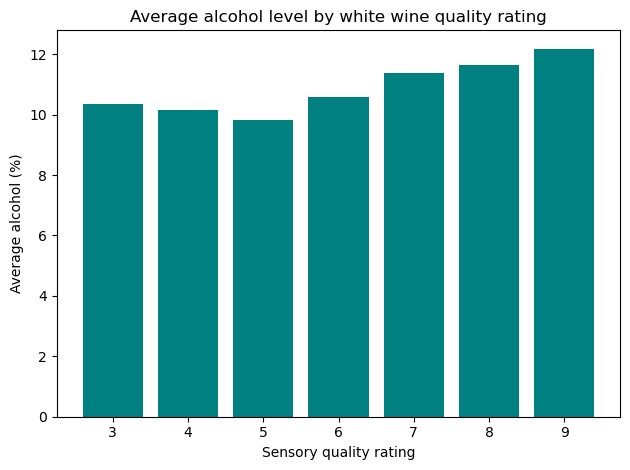

In [6]:
import matplotlib.pyplot as plt

plt.bar(summary["quality"], summary["average_alcohol"], color="teal")
plt.title("Average alcohol level by white wine quality rating")
plt.xlabel("Sensory quality rating")
plt.ylabel("Average alcohol (%)")
plt.xticks(summary["quality"])
plt.tight_layout()
plt.show()

### Alcohol findings

I compared average alcohol levels across sensory quality ratings in a public white wine dataset. Among the 1,457 samples rated 5, the average alcohol level was 9.81%. Among the 880 samples rated 7, it was 11.37%. The wines rated 7 averaged 1.56 percentage points higher in alcohol than the wines rated 5. This comparison shows an association between alcohol level and sensory rating in these two groups.

## pH by sensory quality rating

In [7]:
wine_ph = df[["quality", "pH"]].copy()

print("Missing values:")
print(wine_ph.isna().sum())

summary_ph = (
    wine_ph.groupby("quality")["pH"]
    .agg(samples="size", average_ph="mean")
    .reset_index()
)

display(summary_ph.round(3))

Missing values:
quality    0
pH         0
dtype: int64


,quality,samples,average_ph
0,3,20,3.188
1,4,163,3.183
2,5,1457,3.169
3,6,2198,3.189
4,7,880,3.214
5,8,175,3.219
6,9,5,3.308


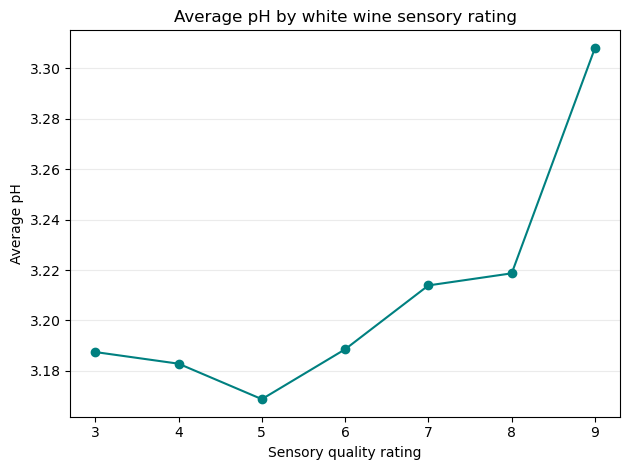

In [8]:
import matplotlib.pyplot as plt

plt.plot(
    summary_ph["quality"],
    summary_ph["average_ph"],
    marker="o",
    color="teal",
)
plt.title("Average pH by white wine sensory rating")
plt.xlabel("Sensory quality rating")
plt.ylabel("Average pH")
plt.xticks(summary_ph["quality"])
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## pH findings

#### Samples rated 5 averaged pH 3.169, while samples rated 7 averaged pH 3.214. The group rated 7 averaged approximately 0.045 pH units higher. These averages describe the groups. A plot of individual measurements would show how much pH varies within each group

## Data checks before modelling

In [11]:
print("Rows in the original dataset:", len(df))
print("Missing values in the full dataset:", df.isna().sum().sum())
print("Repeated full rows:", df.duplicated().sum())

model_data = df.drop_duplicates().copy()

print("Rows after removing repeated full rows:", len(model_data))

Rows in the original dataset: 4898
Missing values in the full dataset: 0
Repeated full rows: 937
Rows after removing repeated full rows: 3961


## Relationships between measurements and ratings

In [12]:
measurements = [
    "alcohol",
    "pH",
    "volatile acidity",
    "residual sugar",
]

correlations = (
    model_data[measurements + ["quality"]]
    .corr(method="spearman")["quality"]
    .drop("quality")
    .sort_values(key=lambda values: values.abs(), ascending=False)
)

display(correlations.round(3))

alcohol             0.476
volatile acidity   -0.185
pH                  0.136
residual sugar     -0.092
Name: quality, dtype: float64

## Correlation findings

#### Alcohol had the strongest association with sensory rating among the four measurements I examined (Spearman correlation 0.476). Higher alcohol levels tended to occur with higher ratings. The association for pH was weaker and positive (0.136). Volatile acidity (−0.185) and residual sugar (−0.092) had negative correlations.

## Predicting sensory quality

In [15]:
from sklearn.model_selection import train_test_split

X = model_data.drop(columns="quality")
y = model_data["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

Training samples: 3168
Test samples: 793


In [16]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

baseline = DummyRegressor(strategy="median")
baseline.fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)

model = LinearRegression()
model.fit(X_train, y_train)
model_predictions = model.predict(X_test)

baseline_mae = mean_absolute_error(y_test, baseline_predictions)
model_mae = mean_absolute_error(y_test, model_predictions)

results = pd.DataFrame({
    "Model": ["Median baseline", "Linear regression"],
    "Test MAE": [baseline_mae, model_mae],
})

display(results.round(3))
print(f"Baseline MAE minus model MAE: {baseline_mae - model_mae:.3f}")

,Model,Test MAE
0,Median baseline,0.648
1,Linear regression,0.597


Baseline MAE minus model MAE: 0.051


## Model performance

#### I trained the models on 3,168 records and evaluated them on 793 held-out records. The median baseline had a mean absolute error (MAE) of 0.648 rating points. Linear regression achieved an MAE of 0.597, a reduction of 0.051 rating points on this test set.

In [17]:
test_results = pd.DataFrame({
    "actual_quality": y_test.to_numpy(),
    "predicted_quality": model_predictions,
})

test_results["absolute_error"] = (
    test_results["actual_quality"] - test_results["predicted_quality"]
).abs()

errors_by_rating = (
    test_results.groupby("actual_quality")["absolute_error"]
    .agg(test_samples="size", mean_absolute_error="mean")
)

display(errors_by_rating.round(3))

,test_samples,mean_absolute_error
actual_quality,,
3,5,2.779
4,30,1.480
5,234,0.565
6,349,0.355
7,145,0.743
8,30,1.718


## Prediction errors by rating

#### The model had an average absolute error of 2.779 points for wines rated 3 (5 test records), compared with 0.355 points for wines rated 6 (349 test records). The estimate for rating 3 is based on very few records.

## CONCLUSION

#### I analysed how alcohol and pH varied across sensory ratings in a public white wine dataset. Wines rated 7 averaged 11.37% alcohol and pH 3.214, while wines rated 5 averaged 9.81% alcohol and pH 3.169. Alcohol had the strongest association with sensory rating among the four measurements I examined.

#### Linear regression achieved a test MAE of 0.597 rating points, compared with 0.648 for the median baseline. The physicochemical measurements provided a modest improvement in prediction on this held-out set.

#### The dataset represents one white wine context, and some ratings had few test records. The findings describe associations with sensory scores. Applying this approach to another beverage would require data from that product and a comparable definition of quality.